In [1]:
import os
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

2026-04-23 23:30:58.048834: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
labels_path = "/Users/rwan/Desktop/data/labels.csv"
images_folder = "/Users/rwan/Desktop/data/frames/frames"

In [3]:
# قراءة ملف CSV
df = pd.read_csv(labels_path)

# عرض أول 5 صفوف للتأكد من شكل البيانات
print("First 5 rows:")
display(df.head())

# عرض أسماء الأعمدة
print("\nColumns:")
print(df.columns.tolist())

# عدد الصفوف (عدد العينات)
print("\nNumber of rows:", len(df))

First 5 rows:


,id,count
0,1,35
1,2,41
2,3,41
3,4,44
4,5,41



Columns:
['id', 'count']

Number of rows: 2000


In [4]:
from tabulate import tabulate

data = [
    ["id", "Image number (used to load image file)"],
    ["count", "Number of people in the image"]
]

print(tabulate(data, headers=["Column Name", "Description"], tablefmt="grid"))

+---------------+----------------------------------------+
| Column Name   | Description                            |
+===============+========================================+
| id            | Image number (used to load image file) |
+---------------+----------------------------------------+
| count         | Number of people in the image          |
+---------------+----------------------------------------+


In [5]:
# ==============================
# 1) تحديد المسارات وقراءة البيانات
# ==============================

# مسار ملف الليبلز
labels_path = "/Users/rwan/Desktop/data/labels.csv"

# مسار مجلد الصور
images_folder = "/Users/rwan/Desktop/data/frames/frames"

# قراءة ملف CSV
df = pd.read_csv(labels_path)

# عرض أول 5 صفوف للتأكد من شكل البيانات
print("أول 5 صفوف من ملف البيانات:")
display(df.head())

# عرض أسماء الأعمدة
print("أسماء الأعمدة:")
print(df.columns.tolist())

# تعريف أسماء الأعمدة المستخدمة
# id = رقم الصورة
# count = عدد الأشخاص في الصورة
id_col = "id"
count_col = "count"

أول 5 صفوف من ملف البيانات:


,id,count
0,1,35
1,2,41
2,3,41
3,4,44
4,5,41


أسماء الأعمدة:
['id', 'count']


In [6]:
# ==========================================
# 2) إحصاء الصور: عددها - صيغها - أبعادها - أحجامها
# ==========================================

# قوائم لتخزين معلومات الصور
missing_images = []      # الصور المفقودة
existing_images = 0      # عدد الصور الموجودة فعليًا
image_extensions = []    # صيغ الصور مثل jpg
image_sizes = []         # أحجام الصور بالكيلوبايت
image_shapes = []        # أبعاد الصور مثل (480, 640, 3)

# المرور على كل صف في ملف البيانات
for _, row in df.iterrows():
    
    # بناء اسم الصورة بالصيغة الصحيحة
    # مثال: id=1 -> seq_000001.jpg
    img_name = f"seq_{int(row[id_col]):06d}.jpg"
    img_path = os.path.join(images_folder, img_name)
    
    # التحقق من وجود الصورة
    if not os.path.exists(img_path):
        missing_images.append(img_name)
        continue
    
    # زيادة عداد الصور الموجودة
    existing_images += 1
    
    # تخزين صيغة الصورة
    ext = os.path.splitext(img_name)[1].lower()
    image_extensions.append(ext)
    
    # تخزين حجم الصورة بالكيلوبايت
    size_kb = os.path.getsize(img_path) / 1024
    image_sizes.append(size_kb)
    
    # قراءة الصورة لاستخراج أبعادها
    img = cv2.imread(img_path)
    if img is not None:
        image_shapes.append(img.shape)

# طباعة الإحصائيات العامة
print("===== إحصائيات عامة عن الصور =====")
print("عدد السجلات في labels.csv:", len(df))
print("عدد الصور الموجودة فعليًا:", existing_images)
print("عدد الصور المفقودة:", len(missing_images))

if len(missing_images) > 0:
    print("أمثلة على الصور المفقودة:")
    print(missing_images[:5])

===== إحصائيات عامة عن الصور =====
عدد السجلات في labels.csv: 2000
عدد الصور الموجودة فعليًا: 2000
عدد الصور المفقودة: 0


In [8]:
# ==========================================
# 3) عرض صيغ الصور وأبعادها وأحجامها
# ==========================================

from collections import Counter

# حساب تكرار كل صيغة صور
format_counts = Counter(image_extensions)

print("===== صيغ الصور =====")
for fmt, cnt in format_counts.items():
    print(f"{fmt}: {cnt}")

# حساب تكرار أبعاد الصور
shape_counts = Counter(image_shapes)

print("\n===== أبعاد الصور =====")
for shape, cnt in shape_counts.most_common(10):
    print(f"{shape}: {cnt}")

# عرض إحصائيات أحجام الصور
print("\n===== أحجام الصور بالكيلوبايت =====")
print("أصغر حجم:", round(min(image_sizes), 2), "KB")
print("أكبر حجم:", round(max(image_sizes), 2), "KB")
print("متوسط الحجم:", round(np.mean(image_sizes), 2), "KB")

===== صيغ الصور =====
.jpg: 2000

===== أبعاد الصور =====
(480, 640, 3): 2000

===== أحجام الصور بالكيلوبايت =====
أصغر حجم: 36.84 KB
أكبر حجم: 47.73 KB
متوسط الحجم: 42.34 KB


In [9]:
# ==========================================
# 4) إحصائيات عدد الأشخاص في الصور
# ==========================================

print("===== إحصائيات عدد الأشخاص =====")
print("أقل عدد أشخاص في صورة:", df[count_col].min())
print("أكبر عدد أشخاص في صورة:", df[count_col].max())
print("المتوسط:", round(df[count_col].mean(), 2))
print("الوسيط:", df[count_col].median())
print("الانحراف المعياري:", round(df[count_col].std(), 2))

===== إحصائيات عدد الأشخاص =====
أقل عدد أشخاص في صورة: 13
أكبر عدد أشخاص في صورة: 53
المتوسط: 31.16
الوسيط: 31.0
الانحراف المعياري: 6.95


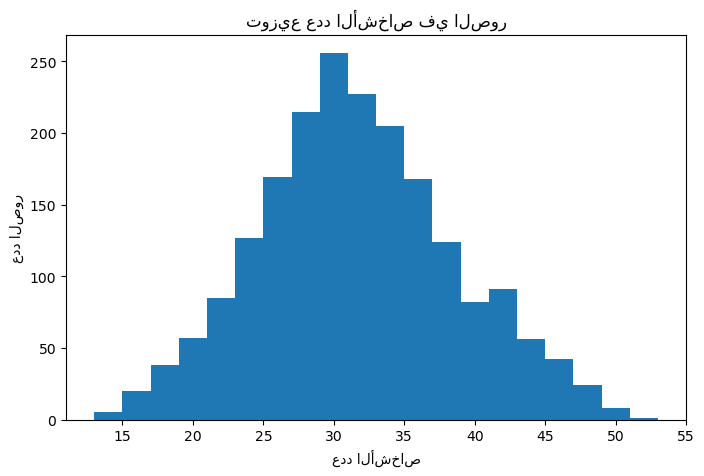

In [10]:
# ==========================================
# 5) رسم توزيع عدد الأشخاص
# ==========================================

# هذا الرسم يوضح كيف تتوزع أعداد الأشخاص في الصور
# ويفيدنا في معرفة هل البيانات متوازنة أو لا

plt.figure(figsize=(8,5))
plt.hist(df[count_col], bins=20)

plt.xlabel("عدد الأشخاص")
plt.ylabel("عدد الصور")
plt.title("توزيع عدد الأشخاص في الصور")

plt.show()

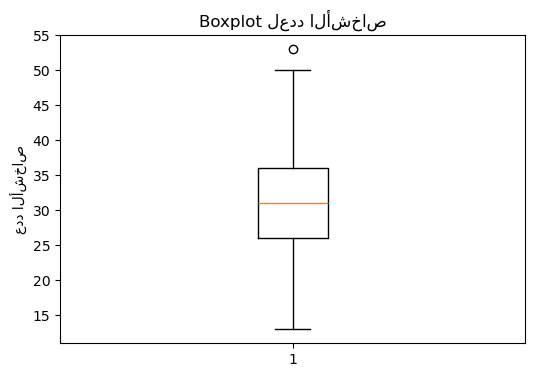

In [11]:
# ==========================================
# 6) رسم Boxplot لمعرفة القيم الشاذة
# ==========================================

# هذا الرسم يساعد في معرفة:
# - أقل قيمة
# - أكبر قيمة
# - القيم الشاذة إن وجدت
# - مكان تمركز أغلب البيانات

plt.figure(figsize=(6,4))
plt.boxplot(df[count_col])

plt.title("Boxplot لعدد الأشخاص")
plt.ylabel("عدد الأشخاص")

plt.show()

In [12]:
# ==========================================
# 7) اختيار صورة عينة من البيانات
# ==========================================

# نختار أول صورة من ملف البيانات لتجربة المعالجة عليها
sample_id = int(df.iloc[0][id_col])

# بناء اسم الصورة
sample_img_name = f"seq_{sample_id:06d}.jpg"
sample_img_path = os.path.join(images_folder, sample_img_name)

print("اسم الصورة المختارة:", sample_img_name)
print("مسار الصورة:", sample_img_path)

# قراءة الصورة بالطريقة الافتراضية في OpenCV (BGR)
img_bgr = cv2.imread(sample_img_path)

# عرض أبعاد الصورة الأصلية
print("أبعاد الصورة الأصلية:", img_bgr.shape)

اسم الصورة المختارة: seq_000001.jpg
مسار الصورة: /Users/rwan/Desktop/data/frames/frames/seq_000001.jpg
أبعاد الصورة الأصلية: (480, 640, 3)


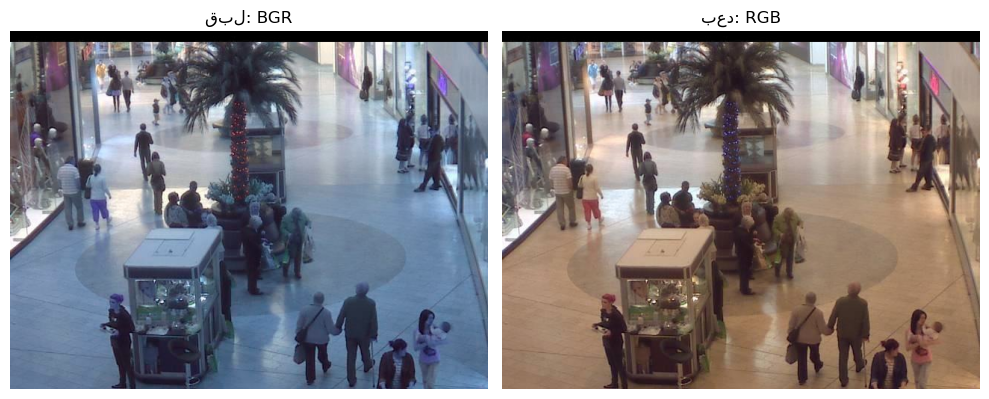

In [13]:
# ==========================================
# 8) تحويل الصورة من BGR إلى RGB
# ==========================================

# OpenCV يقرأ الصور بصيغة BGR
# لكن العرض الصحيح في matplotlib يحتاج RGB
# لذلك هذه الخطوة مهمة لتصحيح الألوان

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# عرض قبل وبعد
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_bgr)
plt.title("قبل: BGR")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_rgb)
plt.title("بعد: RGB")
plt.axis("off")

plt.tight_layout()
plt.show()

أبعاد الصورة قبل التصغير: (480, 640, 3)
أبعاد الصورة بعد التصغير: (128, 128, 3)


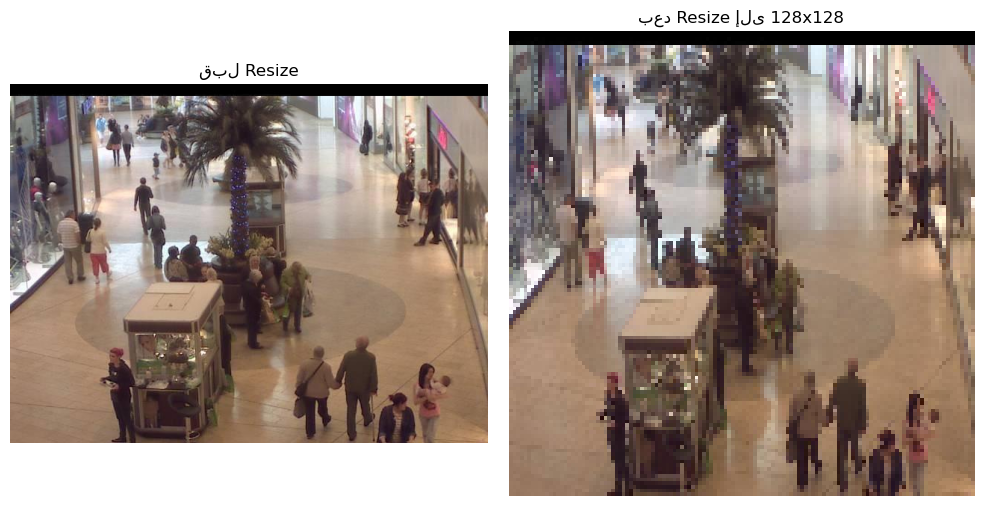

In [14]:
# ==========================================
# 9) تصغير الصورة إلى حجم مناسب للتدريب
# ==========================================

# نستخدم 128x128 لأنك اشتغلتِ عليه في المشروع
# ويمكن لاحقًا تجربة 224x224 إذا احتجتِ
# الهدف من التصغير:
# - توحيد حجم الصور
# - تقليل وقت التدريب
# - تقليل استهلاك الذاكرة

img_resized = cv2.resize(img_rgb, (128, 128))

print("أبعاد الصورة قبل التصغير:", img_rgb.shape)
print("أبعاد الصورة بعد التصغير:", img_resized.shape)

# عرض قبل وبعد
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_rgb)
plt.title("قبل Resize")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_resized)
plt.title("بعد Resize إلى 128x128")
plt.axis("off")

plt.tight_layout()
plt.show()

قبل التطبيع - أقل قيمة: 0 أعلى قيمة: 255
بعد التطبيع - أقل قيمة: 0.0 أعلى قيمة: 1.0


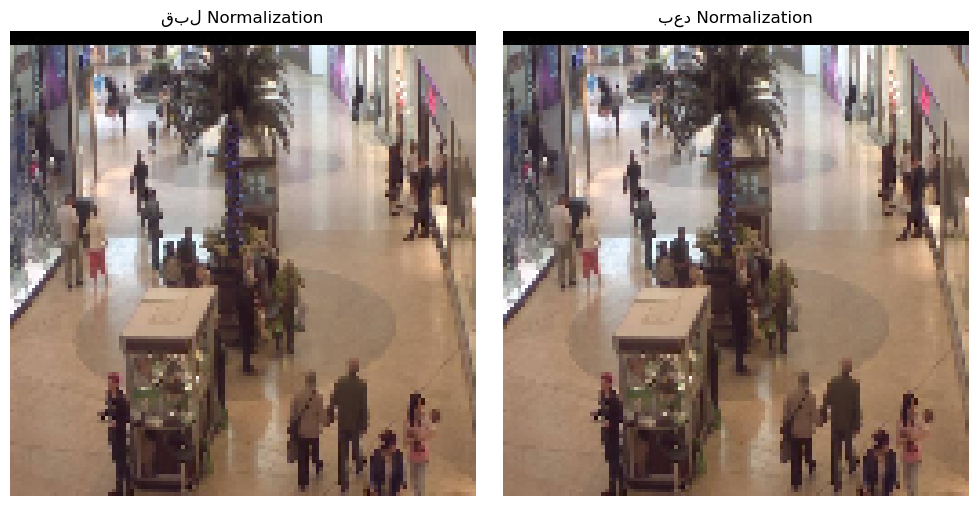

In [15]:
# ==========================================
# 10) تطبيع الصورة Normalization
# ==========================================

# في الصورة الأصلية تكون قيم البكسل من 0 إلى 255
# بعد التطبيع تصبح من 0 إلى 1
# هذه الخطوة تساعد المودل على التعلم بشكل أفضل وأسرع

img_normalized = img_resized / 255.0

print("قبل التطبيع - أقل قيمة:", img_resized.min(), "أعلى قيمة:", img_resized.max())
print("بعد التطبيع - أقل قيمة:", img_normalized.min(), "أعلى قيمة:", img_normalized.max())

# عرض قبل وبعد
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_resized)
plt.title("قبل Normalization")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_normalized)
plt.title("بعد Normalization")
plt.axis("off")

plt.tight_layout()
plt.show()

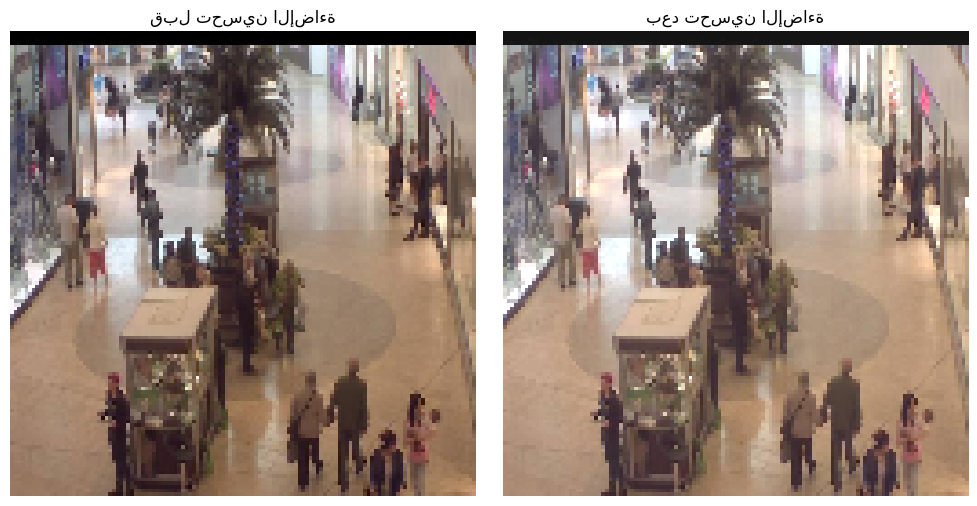

In [16]:
# ==========================================
# 11) تحسين بسيط للإضاءة
# ==========================================

# هذا التعديل البسيط قد يفيد مع صور المراقبة
# لأنه يجعل الصورة أكثر وضوحًا قليلًا
# alpha = التحكم في التباين
# beta = التحكم في السطوع

bright_img = cv2.convertScaleAbs(img_resized, alpha=1.0, beta=20)

# عرض قبل وبعد
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_resized)
plt.title("قبل تحسين الإضاءة")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(bright_img)
plt.title("بعد تحسين الإضاءة")
plt.axis("off")

plt.tight_layout()
plt.show()

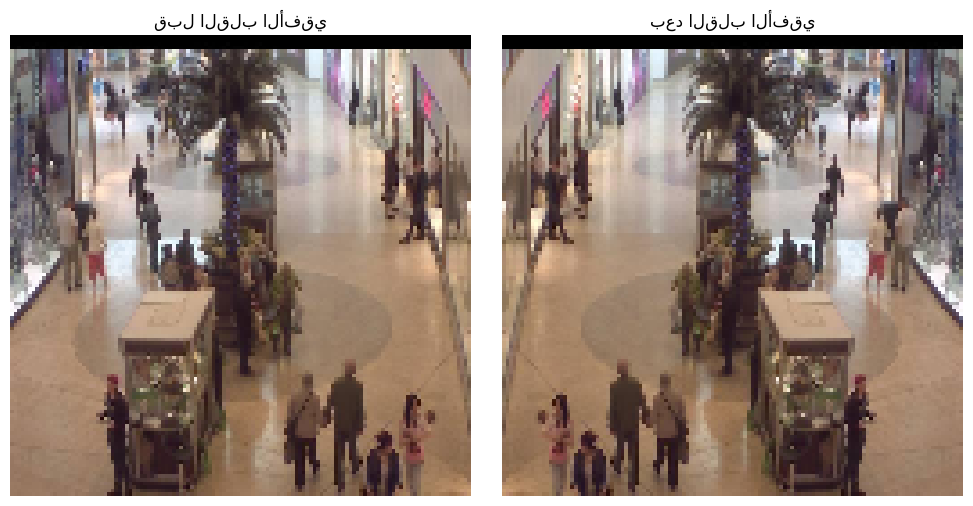

In [17]:
# ==========================================
# 12) القلب الأفقي Horizontal Flip
# ==========================================

# هذه ليست معالجة أساسية للصورة
# لكنها مفيدة كـ augmentation أثناء التدريب
# تساعد المودل على رؤية تنوع أكبر في البيانات

flip_img = cv2.flip(img_resized, 1)

# عرض قبل وبعد
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_resized)
plt.title("قبل القلب الأفقي")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(flip_img)
plt.title("بعد القلب الأفقي")
plt.axis("off")

plt.tight_layout()
plt.show()

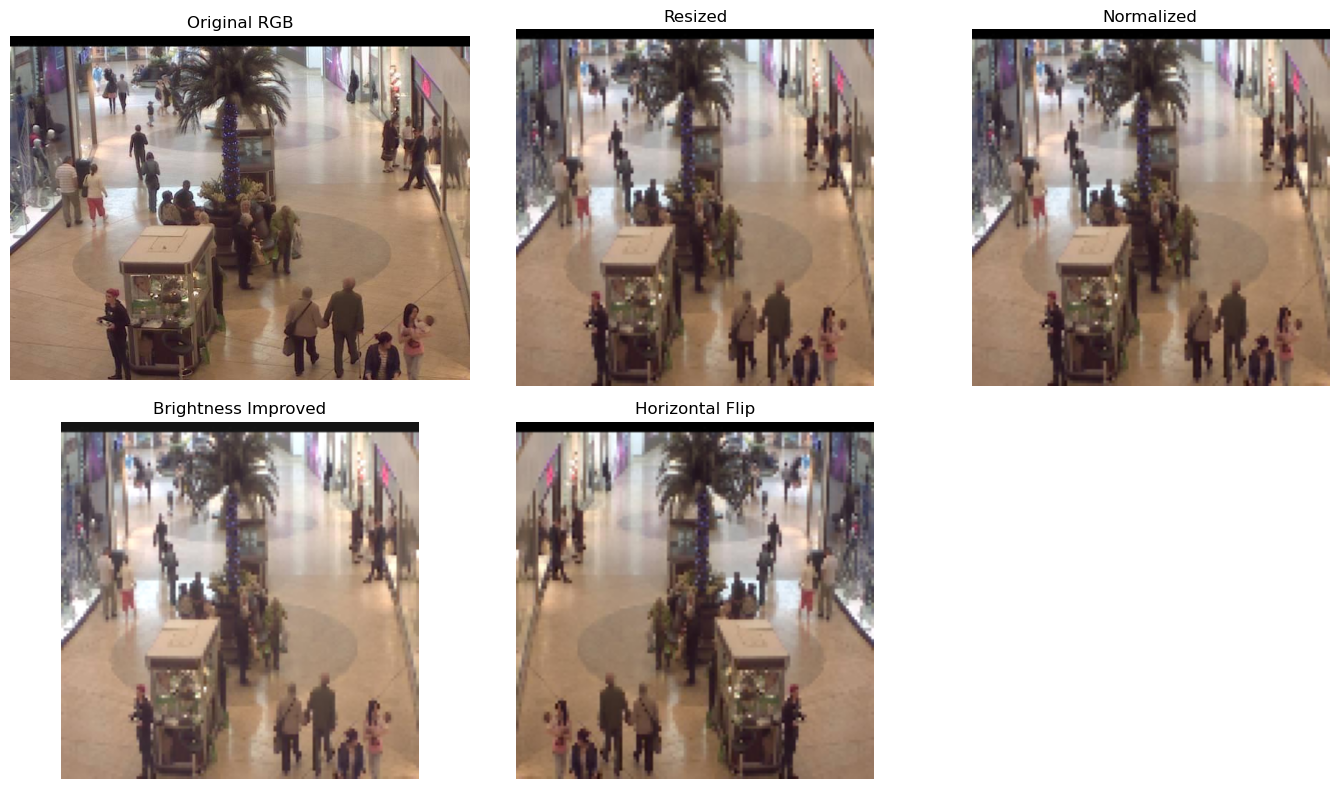

In [18]:
# ==========================================
# 13) عرض ملخص المعالجات في شكل واحد
# ==========================================

# هذا الرسم يجمع أهم النتائج بصريًا
# ليسهل المقارنة بين قبل وبعد

plt.figure(figsize=(14,8))

plt.subplot(2,3,1)
plt.imshow(img_rgb)
plt.title("Original RGB")
plt.axis("off")

plt.subplot(2,3,2)
plt.imshow(img_resized)
plt.title("Resized")
plt.axis("off")

plt.subplot(2,3,3)
plt.imshow(img_normalized)
plt.title("Normalized")
plt.axis("off")

plt.subplot(2,3,4)
plt.imshow(bright_img)
plt.title("Brightness Improved")
plt.axis("off")

plt.subplot(2,3,5)
plt.imshow(flip_img)
plt.title("Horizontal Flip")
plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# ==========================================
# 14) تجهيز جميع الصور للتدريب
# ==========================================

# في هذا الجزء:
# - نقرأ كل الصور
# - نحولها إلى RGB
# - نصغرها إلى 128x128
# - نطبعها إلى المدى [0,1]
# - نخزن القيم الحقيقية (عدد الأشخاص)

images = []
counts = []

for _, row in df.iterrows():
    img_name = f"seq_{int(row[id_col]):06d}.jpg"
    img_path = os.path.join(images_folder, img_name)
    
    # نتأكد أن الصورة موجودة
    if not os.path.exists(img_path):
        continue
    
    # قراءة الصورة
    img = cv2.imread(img_path)
    
    # إذا لم تُقرأ الصورة نتجاوزها
    if img is None:
        continue
    
    # تحويل من BGR إلى RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # تصغير الصورة
    img = cv2.resize(img, (128, 128))
    
    # تطبيع القيم
    img = img / 255.0
    
    # حفظ الصورة والعدد الحقيقي
    images.append(img)
    counts.append(row[count_col])

# تحويل القوائم إلى numpy arrays
X = np.array(images, dtype=np.float32)
y = np.array(counts, dtype=np.float32)

# عرض شكل البيانات النهائية
print("شكل X:", X.shape)
print("شكل y:", y.shape)

شكل X: (2000, 128, 128, 3)
شكل y: (2000,)


In [22]:
# ==========================================
# 3) إنشاء جدول ملخص للإحصائيات
# ==========================================

# هذا الجدول مفيد جدًا للتقرير أو للعرض

stats_df = pd.DataFrame({
    "الإحصائية": ["عدد الصور", "أقل عدد", "أكبر عدد", "المتوسط", "الوسيط", "الانحراف المعياري"],
    "القيمة": [
        len(X),
        int(y.min()),
        int(y.max()),
        round(y.mean(), 2),
        round(np.median(y), 2),
        round(y.std(), 2)
    ]
})

print("===== جدول الإحصائيات =====")
display(stats_df)

===== جدول الإحصائيات =====


,الإحصائية,القيمة
0,عدد الصور,2000.00
1,أقل عدد,13.00
2,أكبر عدد,53.00
3,المتوسط,31.16
4,الوسيط,31.00
5,الانحراف المعياري,6.94


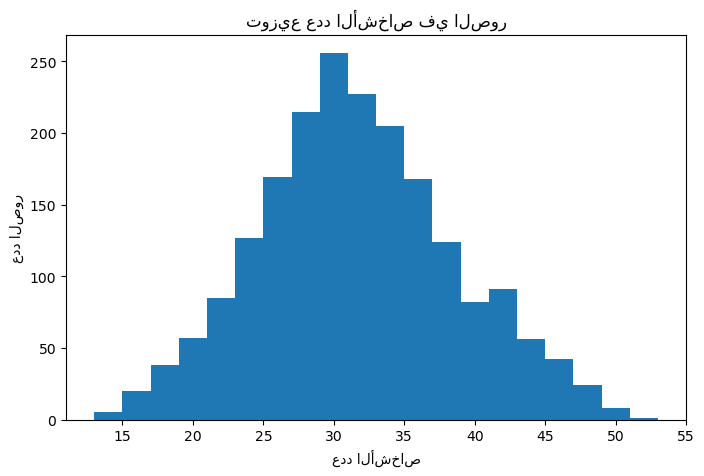

In [23]:
# ==========================================
# 4) رسم توزيع عدد الأشخاص
# ==========================================

# هذا الرسم يوضح كيف تتوزع أعداد الأشخاص في الصور
# ويساعدنا على معرفة هل البيانات متوازنة أو فيها انحياز

plt.figure(figsize=(8,5))

# bins=20 يعني تقسيم الأعداد إلى 20 فئة تقريبًا
plt.hist(y, bins=20)

plt.xlabel("عدد الأشخاص")
plt.ylabel("عدد الصور")
plt.title("توزيع عدد الأشخاص في الصور")

plt.show()

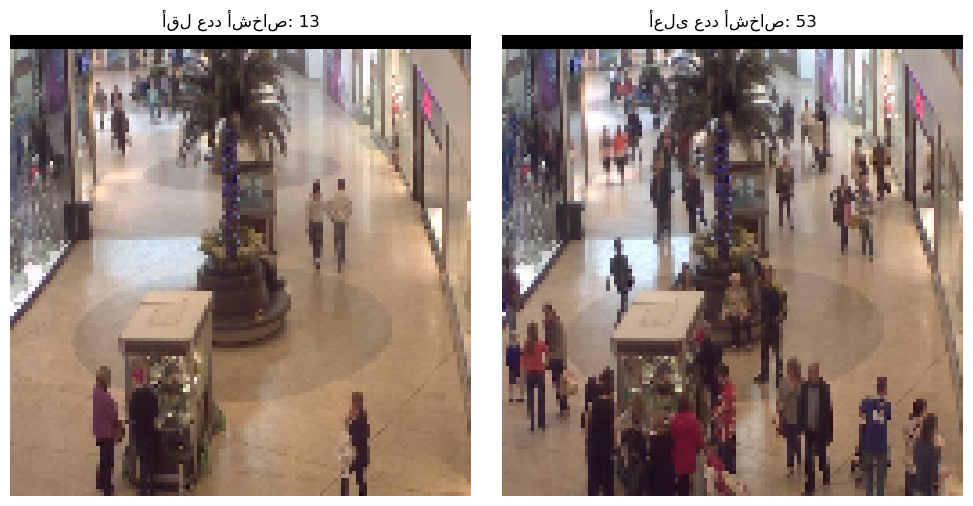

In [24]:
# ==========================================
# 6) عرض صورة أقل عدد وصورة أعلى عدد
# ==========================================

# نحدد مواقع أقل وأعلى قيمة في y
min_idx = np.argmin(y)
max_idx = np.argmax(y)

# عرض الصورتين مع العدد الحقيقي
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(X[min_idx])
plt.title(f"أقل عدد أشخاص: {int(y[min_idx])}")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(X[max_idx])
plt.title(f"أعلى عدد أشخاص: {int(y[max_idx])}")
plt.axis("off")

plt.tight_layout()
plt.show()

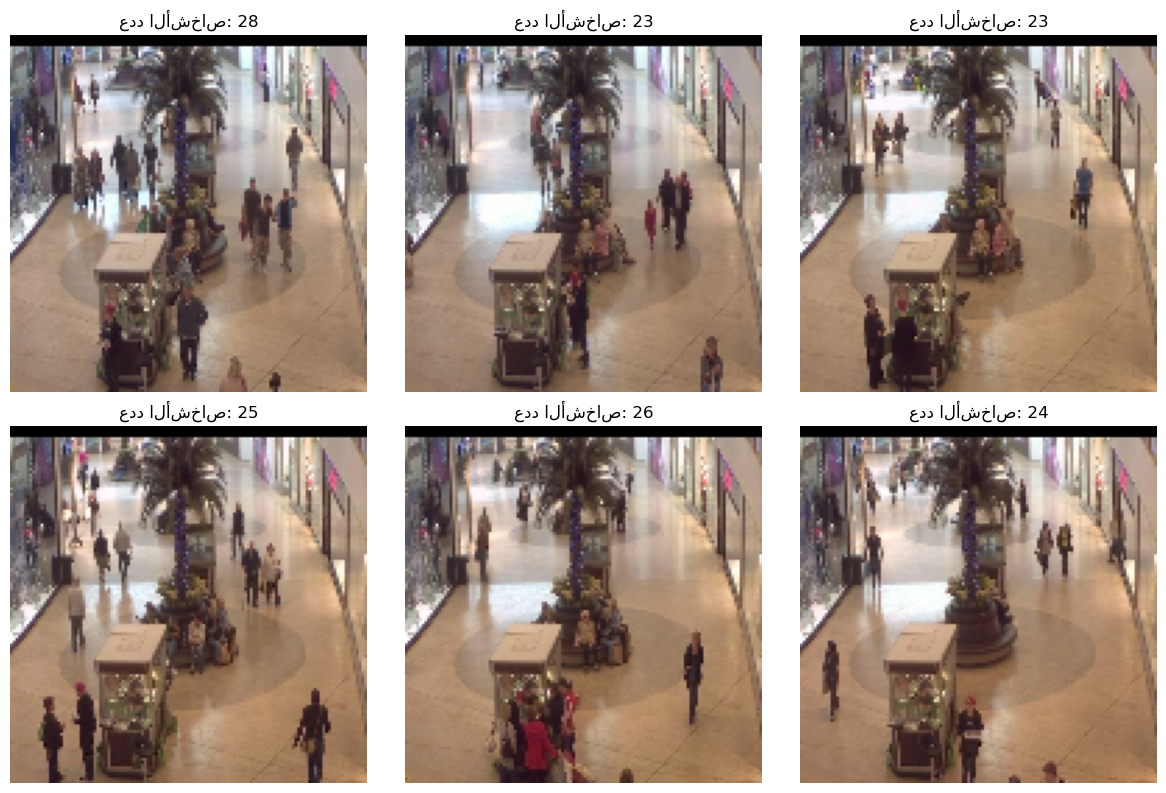

In [25]:
# ==========================================
# 7) عرض عينات عشوائية من البيانات
# ==========================================

# هذا الجزء مفيد جدًا حتى نشوف تنوع الصور والليبلز

plt.figure(figsize=(12,8))

# اختيار 6 صور عشوائية
random_indices = np.random.choice(len(X), 6, replace=False)

for i, idx in enumerate(random_indices):
    plt.subplot(2,3,i+1)
    plt.imshow(X[idx])
    plt.title(f"عدد الأشخاص: {int(y[idx])}")
    plt.axis("off")

plt.tight_layout()
plt.show()

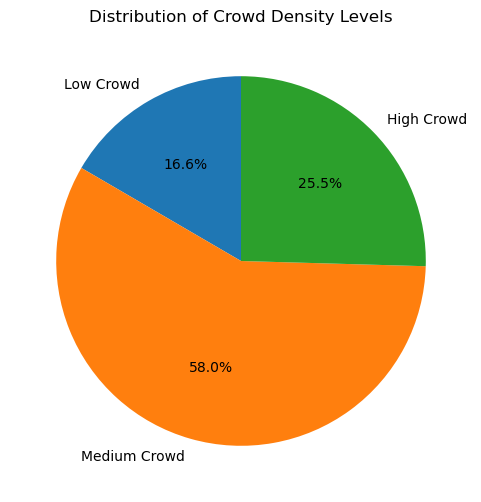

In [26]:
# ==========================================
# 9) تقسيم الصور إلى فئات كثافة وعرضها بشكل دائري
# ==========================================

# نصنف الصور حسب عدد الأشخاص
low_count = np.sum(y < 25)                    # صور قليلة الزحمة
medium_count = np.sum((y >= 25) & (y <= 35)) # صور زحمة متوسطة
high_count = np.sum(y > 35)                   # صور زحمة عالية

sizes = [low_count, medium_count, high_count]
labels = ["Low Crowd", "Medium Crowd", "High Crowd"]

plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title("Distribution of Crowd Density Levels")
plt.show()

In [27]:
# Histogram:
# يوضح توزيع عدد الأشخاص وهل البيانات متوازنة أو لا

# Boxplot:
# يوضح مدى انتشار البيانات والقيم الشاذة

# Min/Max Images:
# يعرض أقل وأعلى ازدحام في الصور

# Random Samples:
# يعرض أمثلة متنوعة من البيانات

# Pie Chart:
# يعطي نظرة سريعة عن كثافة الازدحام

In [28]:
#تقسيم الدالتا


In [29]:
# ==========================================
# 1) تقسيم البيانات إلى Train / Validation / Test
# ==========================================

from sklearn.model_selection import train_test_split

# أول تقسيم:
# نفصل 20% للاختبار
# ويبقى 80% للتدريب + التحقق
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# ثاني تقسيم:
# نأخذ 12.5% من X_temp للتحقق
# وهذا يعطينا 10% من كامل البيانات تقريبًا
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.125,
    random_state=42
)

# عرض أشكال البيانات بعد التقسيم
print("===== أشكال البيانات بعد التقسيم =====")
print("Train shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)

===== أشكال البيانات بعد التقسيم =====
Train shape: (1400, 128, 128, 3) (1400,)
Validation shape: (200, 128, 128, 3) (200,)
Test shape: (400, 128, 128, 3) (400,)


In [30]:
# ==========================================
# 2) عرض عدد الصور في كل مجموعة
# ==========================================

print("===== عدد الصور في كل مجموعة =====")
print("عدد صور التدريب:", len(X_train))
print("عدد صور التحقق:", len(X_val))
print("عدد صور الاختبار:", len(X_test))

===== عدد الصور في كل مجموعة =====
عدد صور التدريب: 1400
عدد صور التحقق: 200
عدد صور الاختبار: 400


In [31]:
# ==========================================
# 3) حساب النسبة الفعلية للتقسيم
# ==========================================

# حساب العدد الكلي
total_images = len(X)

# حساب نسبة كل جزء
train_percent = (len(X_train) / total_images) * 100
val_percent = (len(X_val) / total_images) * 100
test_percent = (len(X_test) / total_images) * 100

print("===== النسب الفعلية =====")
print("نسبة التدريب:", round(train_percent, 2), "%")
print("نسبة التحقق:", round(val_percent, 2), "%")
print("نسبة الاختبار:", round(test_percent, 2), "%")

===== النسب الفعلية =====
نسبة التدريب: 70.0 %
نسبة التحقق: 10.0 %
نسبة الاختبار: 20.0 %


In [70]:
# نستخدم MobileNetV2 بدون الطبقات الأخيرة الخاصة بالتصنيف
# include_top=False يعني نشيل رأس التصنيف الأصلي
# weights='imagenet' يعني نستخدم أوزان مدربة مسبقًا
# input_shape لازم يطابق شكل صورنا الفعلي

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# في البداية نجمد الطبقات الجاهزة
# حتى نستفيد من features الجاهزة بدون تعديلها
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [32]:
# ==========================================
# 4) إنشاء جدول ملخص لتقسيم البيانات
# ==========================================

split_df = pd.DataFrame({
    "المجموعة": ["Training", "Validation", "Testing"],
    "عدد الصور": [len(X_train), len(X_val), len(X_test)],
    "النسبة %": [
        round(train_percent, 2),
        round(val_percent, 2),
        round(test_percent, 2)
    ]
})

print("===== جدول تقسيم البيانات =====")
display(split_df)

===== جدول تقسيم البيانات =====


,المجموعة,عدد الصور,النسبة %
0,Training,1400,70.0
1,Validation,200,10.0
2,Testing,400,20.0


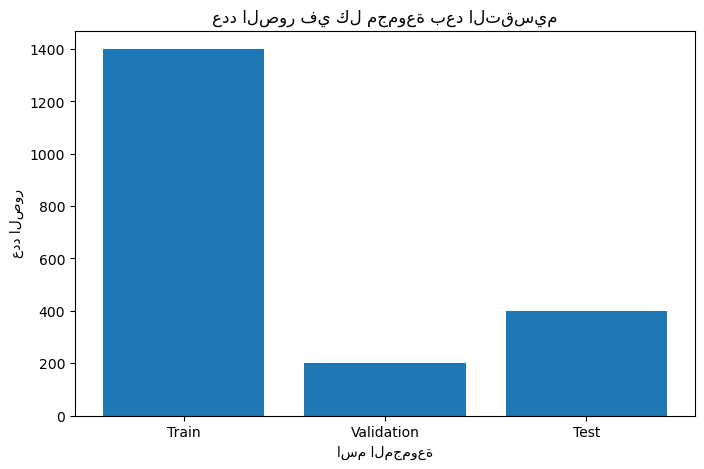

In [33]:
# ==========================================
# 5) رسم بياني عمودي لعدد الصور في كل مجموعة
# ==========================================

# هذا الرسم يوضح عدد الصور في كل جزء من البيانات

plt.figure(figsize=(8,5))

groups = ["Train", "Validation", "Test"]
counts = [len(X_train), len(X_val), len(X_test)]

plt.bar(groups, counts)

plt.xlabel("اسم المجموعة")
plt.ylabel("عدد الصور")
plt.title("عدد الصور في كل مجموعة بعد التقسيم")

plt.show()

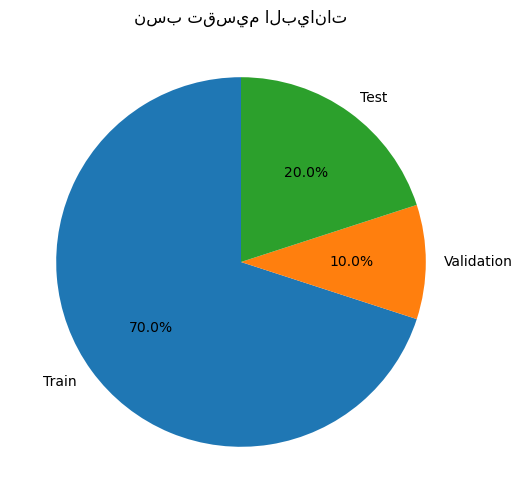

In [34]:
# ==========================================
# 6) رسم دائري يوضح نسب التقسيم
# ==========================================

# هذا الرسم يوضح النسبة المئوية لكل مجموعة بشكل بصري جميل
sizes = [len(X_train), len(X_val), len(X_test)]
labels = ["Train", "Validation", "Test"]

plt.figure(figsize=(6,6))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("نسب تقسيم البيانات")
plt.show()

In [36]:
#تدريب

In [37]:
# ==========================================
# 1) استدعاء مكتبات بناء نموذج CNN
# ==========================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [38]:
# ==========================================
# 2) بناء نموذج CNN من الصفر
# ==========================================

# هذا النموذج يعتبر Deep Learning model
# وهو يحقق أول شرط في المشروع

model = Sequential([
    
    # الطبقة الأولى:
    # استخراج ميزات أولية من الصورة مثل الحواف والأشكال البسيطة
    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D((2,2)),
    
    # الطبقة الثانية:
    # استخراج ميزات أعمق من الصورة
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    
    # الطبقة الثالثة:
    # استخراج تفاصيل أكثر تعقيدًا
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    
    # تحويل خرائط الميزات إلى متجه واحد
    Flatten(),
    
    # طبقة fully connected للتعلم النهائي
    Dense(128, activation='relu'),
    
    # Dropout لتقليل overfitting
    Dropout(0.3),
    
    # طبقة الخرج:
    # نستخدم قيمة واحدة فقط لأن المهمة Regression (توقع عدد الأشخاص)
    Dense(1)
])

/Users/rwan/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [39]:
# ==========================================
# 3) تجهيز النموذج
# ==========================================

# بما أن المهمة هي توقع عدد الأشخاص
# فنحن نتعامل مع Regression وليس Classification

# loss = MSE
# metrics = MAE
# MSE يقيس الخطأ التربيعي
# MAE يقيس متوسط الفرق بين العدد الحقيقي والمتوقع

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# عرض ملخص النموذج
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# ==========================================
# 4) إضافة Early Stopping
# ==========================================

# هذه الخاصية توقف التدريب إذا لم يتحسن الأداء على validation
# فائدتها:
# - تقلل overfitting
# - تمنع إضاعة الوقت في epochs غير مفيدة

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [41]:
# ==========================================
# 5) تدريب النموذج
# ==========================================

# هنا يبدأ النموذج بالتعلم من بيانات التدريب
# ونراقب أداءه على بيانات التحقق

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 18s 359ms/step - loss: 133.2338 - mae: 8.7684 - val_loss: 58.4344 - val_mae: 5.9376
Epoch 2/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 16s 361ms/step - loss: 63.3281 - mae: 6.3405 - val_loss: 49.3953 - val_mae: 5.8183
Epoch 3/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 16s 354ms/step - loss: 59.6836 - mae: 6.1487 - val_loss: 32.2910 - val_mae: 4.4410
Epoch 4/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 15s 341ms/step - loss: 43.9510 - mae: 5.3112 - val_loss: 30.0801 - val_mae: 4.2812
Epoch 5/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 15s 341ms/step - loss: 34.9624 - mae: 4.6560 - val_loss: 15.9503 - val_mae: 3.2333
Epoch 6/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 15s 342ms/step - loss: 29.8768 - mae: 4.3641 - val_loss: 27.7621 - val_mae: 4.4116
Epoch 7/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 15s 349ms/step - loss: 37.6335 - mae: 4.8518 - val_loss: 37.7758 - val_mae: 5.1277
Epoch 8/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 15s 348ms/step - loss: 27.2553 - mae: 4.1182 - val_loss: 13.3724 - val_mae: 2.9915
Epoch 9/30
44/44 ━━━━━━━━━━━━━━

In [48]:
# ==========================================
# 7) حساب نسبة تقريبية للأداء
# ==========================================

# ملاحظة:
# هذه ليست Accuracy رسمية لأن المهمة Regression (توقع عدد)
# لكنها تعطي فكرة تقريبية عن مدى قرب التوقعات من القيم الحقيقية

mean_count = y_test.mean()
approx_performance = (1 - (test_mae / mean_count)) * 100

print("Average true count in test set:", round(mean_count, 2))
print("Approximate performance percentage:", round(approx_performance, 2), "%")

Average true count in test set: 31.14
Approximate performance percentage: 92.68 %


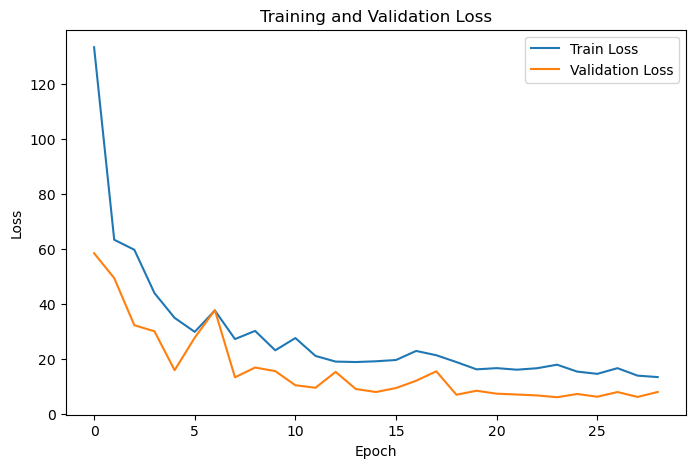

In [44]:
# ==========================================
# 8) رسم منحنى Loss أثناء التدريب
# ==========================================

# هذا الرسم يوضح كيف انخفض الخطأ أثناء التدريب
# إذا كان خط validation قريب من training فهذا شيء جيد

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.show()

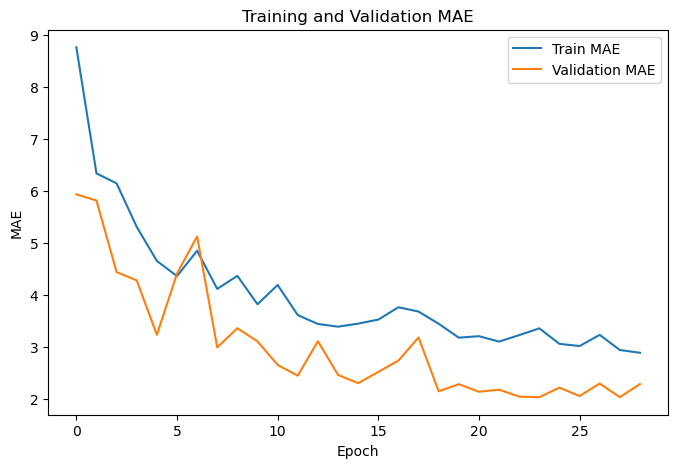

In [45]:
# ==========================================
# 9) رسم منحنى MAE أثناء التدريب
# ==========================================

# هذا الرسم يوضح تغير متوسط الخطأ المطلق
# وكلما انخفض MAE كان النموذج أفضل

plt.figure(figsize=(8,5))

plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training and Validation MAE")
plt.legend()

plt.show()

In [50]:
# ==========================================
# توليد التوقعات من النموذج
# ==========================================

predictions = model.predict(X_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 121ms/step


In [51]:
# ==========================================
# حساب مقاييس إضافية للأداء
# ==========================================

from sklearn.metrics import r2_score

# توليد التوقعات
predictions = model.predict(X_test)

# RMSE
rmse = np.sqrt(test_loss)

# R²
r2 = r2_score(y_test, predictions)

# MAPE
mape = np.mean(np.abs((y_test - predictions.flatten()) / y_test)) * 100

print("===== Additional Metrics =====")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 3))
print("MAPE:", round(mape, 2), "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step
===== Additional Metrics =====
MAE: 2.28
RMSE: 2.89
R² Score: 0.83
MAPE: 7.52 %


In [52]:
#خورزمية ثانيه 

In [54]:
# ==========================================
# 1) استدعاء مكتبات بناء مودل CSRNet-inspired
# ==========================================

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [55]:
# ==========================================
# 2) بناء مودل CSRNet-inspired
# ==========================================

# هذا المودل مستوحى من CSRNet
# الفكرة الأساسية:
# - جزء أمامي لاستخراج الميزات
# - جزء خلفي يستخدم Dilated Convolutions
# - في النهاية يخرج رقمًا واحدًا يمثل عدد الأشخاص

input_layer = Input(shape=(128, 128, 3))

# ------------------------------------------
# Front-end: استخراج الميزات الأساسية
# ------------------------------------------

x = Conv2D(64, (3,3), activation='relu', padding='same')(input_layer)
x = BatchNormalization()(x)
x = Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

x = Conv2D(128, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = Conv2D(128, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

x = Conv2D(256, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = Conv2D(256, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = Conv2D(256, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

# ------------------------------------------
# Back-end: Dilated Convolutions
# ------------------------------------------

x = Conv2D(256, (3,3), activation='relu', padding='same', dilation_rate=2)(x)
x = BatchNormalization()(x)

x = Conv2D(256, (3,3), activation='relu', padding='same', dilation_rate=2)(x)
x = BatchNormalization()(x)

x = Conv2D(128, (3,3), activation='relu', padding='same', dilation_rate=2)(x)
x = BatchNormalization()(x)

x = Conv2D(64, (3,3), activation='relu', padding='same', dilation_rate=2)(x)
x = BatchNormalization()(x)

# ------------------------------------------
# Regression Head
# ------------------------------------------

x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)

output_layer = Dense(1)(x)

csrnet_model = Model(inputs=input_layer, outputs=output_layer)

In [56]:
# ==========================================
# 3) تجهيز مودل CSRNet-inspired
# ==========================================

# لأن المهمة Regression:
# loss = MSE
# metric = MAE

csrnet_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

csrnet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 256)    │       590,08

 Total params: 3,300,353 (12.59 MB)

 Trainable params: 3,296,641 (12.58 MB)

 Non-trainable params: 3,712 (14.50 KB)

In [57]:
# ==========================================
# 4) إيقاف مبكر للتدريب
# ==========================================

# يوقف التدريب إذا لم يتحسن الأداء على validation
# ويسترجع أفضل أوزان

early_stop_csr = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [58]:
# ==========================================
# 5) تدريب مودل CSRNet-inspired
# ==========================================

history_csr = csrnet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop_csr]
)

Epoch 1/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 226s 5s/step - loss: 597.8727 - mae: 22.6542 - val_loss: 421.6500 - val_mae: 19.4508
Epoch 2/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 225s 5s/step - loss: 137.0813 - mae: 9.1262 - val_loss: 5598.7061 - val_mae: 74.6258
Epoch 3/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 220s 5s/step - loss: 84.4006 - mae: 7.1767 - val_loss: 63.9933 - val_mae: 6.5793
Epoch 4/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 217s 5s/step - loss: 58.8251 - mae: 6.1040 - val_loss: 422.8749 - val_mae: 19.4481
Epoch 5/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 215s 5s/step - loss: 45.3115 - mae: 5.3477 - val_loss: 822.3375 - val_mae: 27.8702
Epoch 6/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 219s 5s/step - loss: 38.7670 - mae: 4.8807 - val_loss: 223.7159 - val_mae: 13.4729
Epoch 7/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 222s 5s/step - loss: 33.9928 - mae: 4.6427 - val_loss: 482.5039 - val_mae: 20.9471
Epoch 8/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 217s 5s/step - loss: 33.7065 - mae: 4.6156 - val_loss: 385.1408 - val_mae: 18.7314


In [59]:
# ==========================================
# 6) تقييم مودل CSRNet-inspired
# ==========================================

csr_test_loss, csr_test_mae = csrnet_model.evaluate(X_test, y_test)

print("===== CSRNet-inspired Test Results =====")
print("Test MSE:", round(csr_test_loss, 2))
print("Test MAE:", round(csr_test_mae, 2))

13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - loss: 67.7381 - mae: 6.7935
===== CSRNet-inspired Test Results =====
Test MSE: 67.74
Test MAE: 6.79


In [60]:
# ==========================================
# 7) حساب مقاييس إضافية لمودل CSRNet-inspired
# ==========================================

from sklearn.metrics import r2_score

# توليد التوقعات
csr_predictions = csrnet_model.predict(X_test)

# RMSE
csr_rmse = np.sqrt(csr_test_loss)

# R²
csr_r2 = r2_score(y_test, csr_predictions.flatten())

# MAPE
csr_mape = np.mean(np.abs((y_test - csr_predictions.flatten()) / y_test)) * 100

# نسبة تقريبية للأداء
csr_mean_count = y_test.mean()
csr_approx_performance = (1 - (csr_test_mae / csr_mean_count)) * 100

print("===== CSRNet-inspired Additional Metrics =====")
print("MAE:", round(csr_test_mae, 2))
print("RMSE:", round(csr_rmse, 2))
print("R² Score:", round(csr_r2, 3))
print("MAPE:", round(csr_mape, 2), "%")
print("Approximate performance percentage:", round(csr_approx_performance, 2), "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step
===== CSRNet-inspired Additional Metrics =====
MAE: 6.79
RMSE: 8.23
R² Score: -0.381
MAPE: 26.07 %
Approximate performance percentage: 78.18 %


In [61]:
# ==========================================
# 10) جدول تنبؤات CSRNet-inspired
# ==========================================

csr_results_df = pd.DataFrame({
    "True Count": y_test[:10].astype(int),
    "Predicted Count": csr_predictions[:10].flatten().round(2)
})

csr_results_df["Absolute Error"] = abs(
    csr_results_df["True Count"] - csr_results_df["Predicted Count"]
).round(2)

display(csr_results_df)

,True Count,Predicted Count,Absolute Error
0,30,35.610001,5.61
1,34,36.130001,2.13
2,45,36.410000,8.59
3,42,35.810001,6.19
4,25,35.860001,10.86
5,33,35.360001,2.36
6,31,35.369999,4.37
7,44,35.549999,8.45
8,27,36.029999,9.03
9,36,36.290001,0.29


In [62]:
# ==========================================
# 12) مقارنة CNN مع CSRNet-inspired
# ==========================================

comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "CSRNet-inspired"],
    "Test MSE": [round(test_loss, 2), round(csr_test_loss, 2)],
    "Test MAE": [round(test_mae, 2), round(csr_test_mae, 2)],
    "RMSE": [round(rmse, 2), round(csr_rmse, 2)],
    "R² Score": [round(r2, 3), round(csr_r2, 3)],
    "MAPE %": [round(mape, 2), round(csr_mape, 2)],
    "Approx. Performance %": [round(approx_performance, 2), round(csr_approx_performance, 2)]
})

print("===== Model Comparison =====")
display(comparison_df)

===== Model Comparison =====


,Model,Test MSE,Test MAE,RMSE,R² Score,MAPE %,Approx. Performance %
0,Custom CNN,8.35,2.28,2.89,0.830,7.52,92.68
1,CSRNet-inspired,67.74,6.79,8.23,-0.381,26.07,78.18


In [63]:
# ==========================================
# 14) تحديد المودل الأفضل
# ==========================================

# في regression:
# الأقل في MAE و RMSE و MSE أفضل
# الأعلى في R² و Approx. Performance أفضل

if csr_test_mae < test_mae:
    print("CSRNet-inspired performs better than Custom CNN based on MAE.")
else:
    print("Custom CNN performs better than CSRNet-inspired based on MAE.")

if csr_r2 > r2:
    print("CSRNet-inspired has a better R² score.")
else:
    print("Custom CNN has a better R² score.")

Custom CNN performs better than CSRNet-inspired based on MAE.
Custom CNN has a better R² score.


In [64]:
#الشرط الثاني 

In [65]:
# ==========================================
# 1) استدعاء مكتبات Transfer Learning
# ==========================================

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import r2_score

In [66]:
# ==========================================
# 2) تجهيز البيانات لمودل MobileNetV2
# ==========================================

# MobileNetV2 يفضل استخدام preprocess_input الخاص فيه
# لذلك نجهز نسخة جديدة من البيانات بدل ما نغير X الأصلية

X_train_m = preprocess_input((X_train * 255.0).copy())
X_val_m   = preprocess_input((X_val * 255.0).copy())
X_test_m  = preprocess_input((X_test * 255.0).copy())

print("X_train_m shape:", X_train_m.shape)
print("X_val_m shape:", X_val_m.shape)
print("X_test_m shape:", X_test_m.shape)

X_train_m shape: (1400, 128, 128, 3)
X_val_m shape: (200, 128, 128, 3)
X_test_m shape: (400, 128, 128, 3)


In [67]:
# ==========================================
# 3) بناء MobileNetV2 بدون الرأس الأصلي
# ==========================================

# نستخدم weights='imagenet' للاستفادة من أوزان جاهزة
# include_top=False لأننا لا نريد طبقة التصنيف الأصلية
# input_shape يجب أن يطابق شكل صورنا

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# في البداية نجمد الطبقات الجاهزة
# حتى نستفيد من الميزات المستخرجة بدون تعديل الأوزان
base_model.trainable = False

In [68]:
# ==========================================
# 4) بناء مودل MobileNetV2 الكامل
# ==========================================

inputs = Input(shape=(128, 128, 3))

# تمرير الصور خلال المودل الجاهز
x = base_model(inputs, training=False)

# تحويل خرائط الميزات إلى متجه
x = GlobalAveragePooling2D()(x)

# طبقة fully connected
x = Dense(128, activation='relu')(x)

# Dropout لتقليل overfitting
x = Dropout(0.3)(x)

# طبقة الخرج: قيمة واحدة لأن المهمة Regression
outputs = Dense(1)(x)

mobilenet_model = Model(inputs, outputs)

In [69]:
# ==========================================
# 5) تجهيز مودل MobileNetV2
# ==========================================

# loss = MSE
# metric = MAE

mobilenet_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

mobilenet_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [70]:
# ==========================================
# 6) إيقاف مبكر للتدريب
# ==========================================

early_stop_m = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [71]:
# ==========================================
# 7) تدريب مودل MobileNetV2
# ==========================================

history_m = mobilenet_model.fit(
    X_train_m, y_train,
    validation_data=(X_val_m, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop_m]
)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 22s 362ms/step - loss: 139.0191 - mae: 8.6718 - val_loss: 28.6812 - val_mae: 4.2826
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 330ms/step - loss: 37.3468 - mae: 4.8385 - val_loss: 23.4710 - val_mae: 3.7608
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 324ms/step - loss: 29.5082 - mae: 4.2854 - val_loss: 20.9972 - val_mae: 3.5851
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 326ms/step - loss: 24.6479 - mae: 3.9535 - val_loss: 18.5496 - val_mae: 3.4205
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 15s 339ms/step - loss: 22.9765 - mae: 3.7639 - val_loss: 16.4703 - val_mae: 3.2637
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 311ms/step - loss: 21.0596 - mae: 3.6169 - val_loss: 15.5050 - val_mae: 3.1645
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 315ms/step - loss: 20.2006 - mae: 3.5481 - val_loss: 15.0553 - val_mae: 3.1278
Epoch 8/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 315ms/step - loss: 20.2367 - mae: 3.5517 - val_loss: 14.2706 - val_mae: 3.0626
Epoch 9/20
44/44 ━━━━━━━━━━━━━━

In [72]:
# ==========================================
# 8) تقييم مودل MobileNetV2
# ==========================================

m_test_loss, m_test_mae = mobilenet_model.evaluate(X_test_m, y_test)

print("===== MobileNetV2 Test Results =====")
print("Test MSE:", round(m_test_loss, 2))
print("Test MAE:", round(m_test_mae, 2))

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 257ms/step - loss: 11.3634 - mae: 2.6883
===== MobileNetV2 Test Results =====
Test MSE: 11.36
Test MAE: 2.69


In [73]:
# ==========================================
# 9) حساب مقاييس إضافية لمودل MobileNetV2
# ==========================================

# توليد التوقعات
m_predictions = mobilenet_model.predict(X_test_m)

# RMSE
m_rmse = np.sqrt(m_test_loss)

# R²
m_r2 = r2_score(y_test, m_predictions.flatten())

# MAPE
m_mape = np.mean(np.abs((y_test - m_predictions.flatten()) / y_test)) * 100

# نسبة تقريبية للأداء
m_mean_count = y_test.mean()
m_approx_performance = (1 - (m_test_mae / m_mean_count)) * 100

print("===== MobileNetV2 Additional Metrics =====")
print("MAE:", round(m_test_mae, 2))
print("RMSE:", round(m_rmse, 2))
print("R² Score:", round(m_r2, 3))
print("MAPE:", round(m_mape, 2), "%")
print("Approximate performance percentage:", round(m_approx_performance, 2), "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 345ms/step
===== MobileNetV2 Additional Metrics =====
MAE: 2.69
RMSE: 3.37
R² Score: 0.768
MAPE: 8.79 %
Approximate performance percentage: 91.37 %


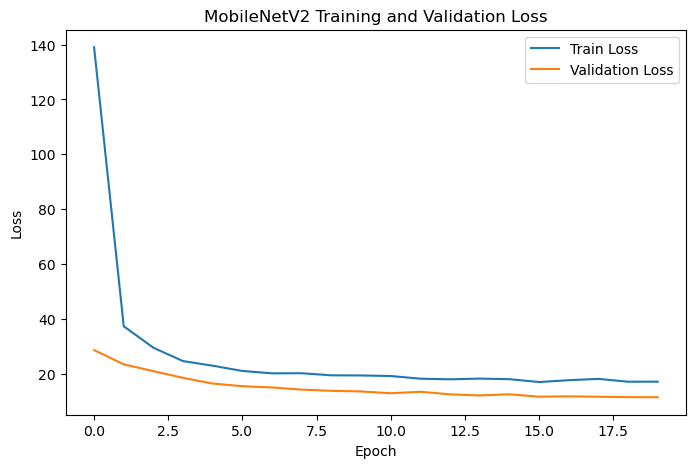

In [74]:
# ==========================================
# 10) رسم منحنى Loss
# ==========================================

plt.figure(figsize=(8,5))

plt.plot(history_m.history['loss'], label='Train Loss')
plt.plot(history_m.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Training and Validation Loss")
plt.legend()
plt.show()

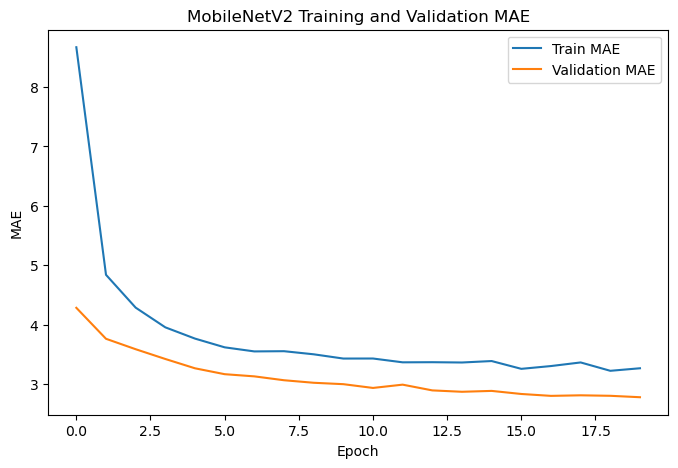

In [75]:
# ==========================================
# 11) رسم منحنى MAE
# ==========================================

plt.figure(figsize=(8,5))

plt.plot(history_m.history['mae'], label='Train MAE')
plt.plot(history_m.history['val_mae'], label='Validation MAE')

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("MobileNetV2 Training and Validation MAE")
plt.legend()
plt.show()

In [76]:
# ==========================================
# 12) جدول تنبؤات MobileNetV2
# ==========================================

m_results_df = pd.DataFrame({
    "True Count": y_test[:10].astype(int),
    "Predicted Count": m_predictions[:10].flatten().round(2)
})

m_results_df["Absolute Error"] = abs(
    m_results_df["True Count"] - m_results_df["Predicted Count"]
).round(2)

display(m_results_df)

,True Count,Predicted Count,Absolute Error
0,30,37.779999,7.78
1,34,32.490002,1.51
2,45,37.430000,7.57
3,42,37.270000,4.73
4,25,24.639999,0.36
5,33,28.270000,4.73
6,31,29.080000,1.92
7,44,38.430000,5.57
8,27,31.240000,4.24
9,36,37.430000,1.43


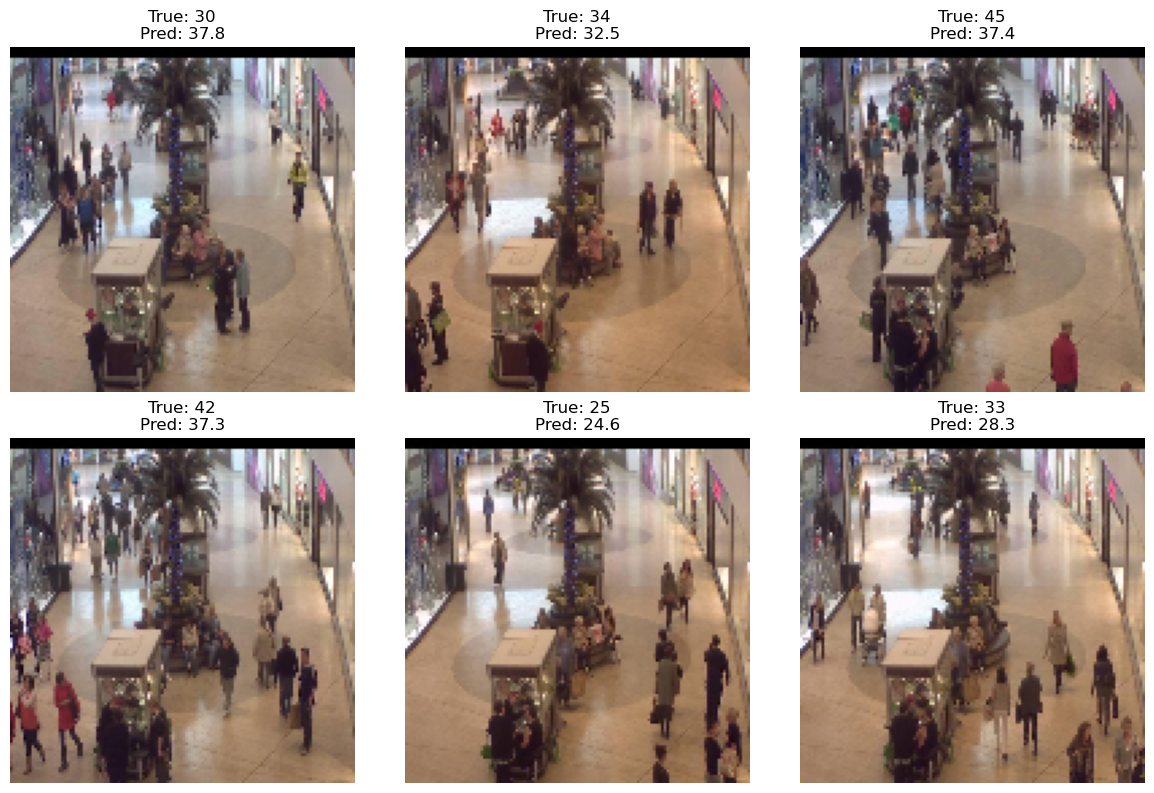

In [77]:
# ==========================================
# 13) عرض صور من test مع توقعات MobileNetV2
# ==========================================

plt.figure(figsize=(12,8))

for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(X_test[i])
    plt.title(f"True: {int(y_test[i])}\nPred: {m_predictions[i][0]:.1f}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [78]:
# ==========================================
# 14) مقارنة نهائية بين جميع المودلات
# ==========================================

final_comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "CSRNet-inspired", "MobileNetV2"],
    "Test MSE": [
        round(test_loss, 2),
        round(csr_test_loss, 2),
        round(m_test_loss, 2)
    ],
    "Test MAE": [
        round(test_mae, 2),
        round(csr_test_mae, 2),
        round(m_test_mae, 2)
    ],
    "RMSE": [
        round(rmse, 2),
        round(csr_rmse, 2),
        round(m_rmse, 2)
    ],
    "R² Score": [
        round(r2, 3),
        round(csr_r2, 3),
        round(m_r2, 3)
    ],
    "MAPE %": [
        round(mape, 2),
        round(csr_mape, 2),
        round(m_mape, 2)
    ],
    "Approx. Performance %": [
        round(approx_performance, 2),
        round(csr_approx_performance, 2),
        round(m_approx_performance, 2)
    ]
})

print("===== Final Model Comparison =====")
display(final_comparison_df)

===== Final Model Comparison =====


,Model,Test MSE,Test MAE,RMSE,R² Score,MAPE %,Approx. Performance %
0,Custom CNN,8.35,2.28,2.89,0.830,7.52,92.68
1,CSRNet-inspired,67.74,6.79,8.23,-0.381,26.07,78.18
2,MobileNetV2,11.36,2.69,3.37,0.768,8.79,91.37


In [79]:
# ==========================================
# 17) تحديد أفضل مودل تلقائيًا
# ==========================================

# الأقل MAE أفضل
all_mae = {
    "Custom CNN": test_mae,
    "CSRNet-inspired": csr_test_mae,
    "MobileNetV2": m_test_mae
}

best_model = min(all_mae, key=all_mae.get)

print("Best model based on MAE:", best_model)

Best model based on MAE: Custom CNN


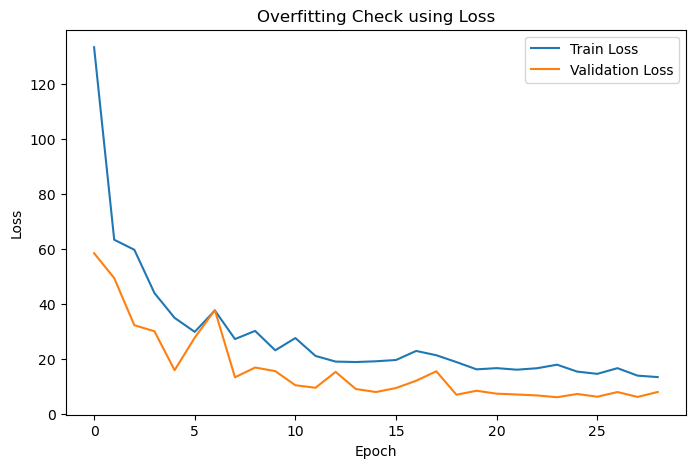

In [80]:
# ==========================================
# 1) رسم Loss لملاحظة الـ Overfitting
# ==========================================

# الفكرة:
# إذا كان Train Loss ينخفض كثير بينما Validation Loss يتوقف أو يرتفع
# فهذا يدل على وجود overfitting

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Overfitting Check using Loss")
plt.legend()
plt.show()

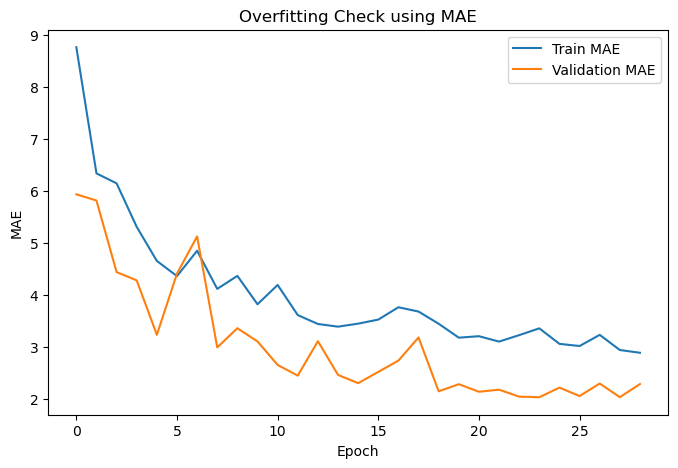

In [81]:
# ==========================================
# 2) رسم MAE لملاحظة الـ Overfitting
# ==========================================

# الفكرة:
# إذا كان Train MAE يتحسن كثير و Validation MAE يبقى أعلى بفارق كبير
# فهذا قد يدل على overfitting

plt.figure(figsize=(8,5))

plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Overfitting Check using MAE")
plt.legend()
plt.show()

In [82]:
# ==========================================
# 3) قياس فرق Train و Validation رقميًا
# ==========================================

# هذا يعطينا فكرة رقمية:
# كلما كان الفرق صغيرًا كان التعميم أفضل

final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]

final_train_mae = history.history['mae'][-1]
final_val_mae = history.history['val_mae'][-1]

print("Final Train Loss:", round(final_train_loss, 2))
print("Final Validation Loss:", round(final_val_loss, 2))
print("Loss Gap:", round(final_val_loss - final_train_loss, 2))

print("Final Train MAE:", round(final_train_mae, 2))
print("Final Validation MAE:", round(final_val_mae, 2))
print("MAE Gap:", round(final_val_mae - final_train_mae, 2))

Final Train Loss: 13.46
Final Validation Loss: 8.05
Loss Gap: -5.41
Final Train MAE: 2.89
Final Validation MAE: 2.29
MAE Gap: -0.6


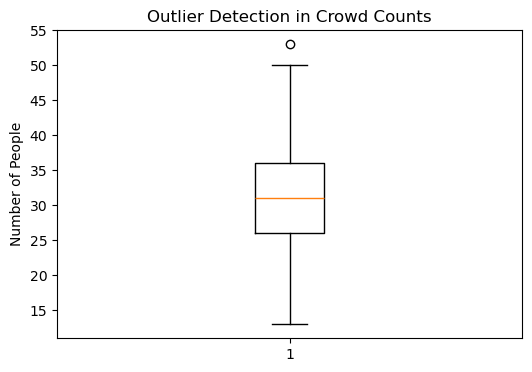

In [83]:
# ==========================================
# 4) Boxplot لاكتشاف Outliers في البيانات
# ==========================================

# هذا الرسم يوضح القيم الشاذة في عدد الأشخاص داخل الصور

plt.figure(figsize=(6,4))
plt.boxplot(y)

plt.title("Outlier Detection in Crowd Counts")
plt.ylabel("Number of People")
plt.show()

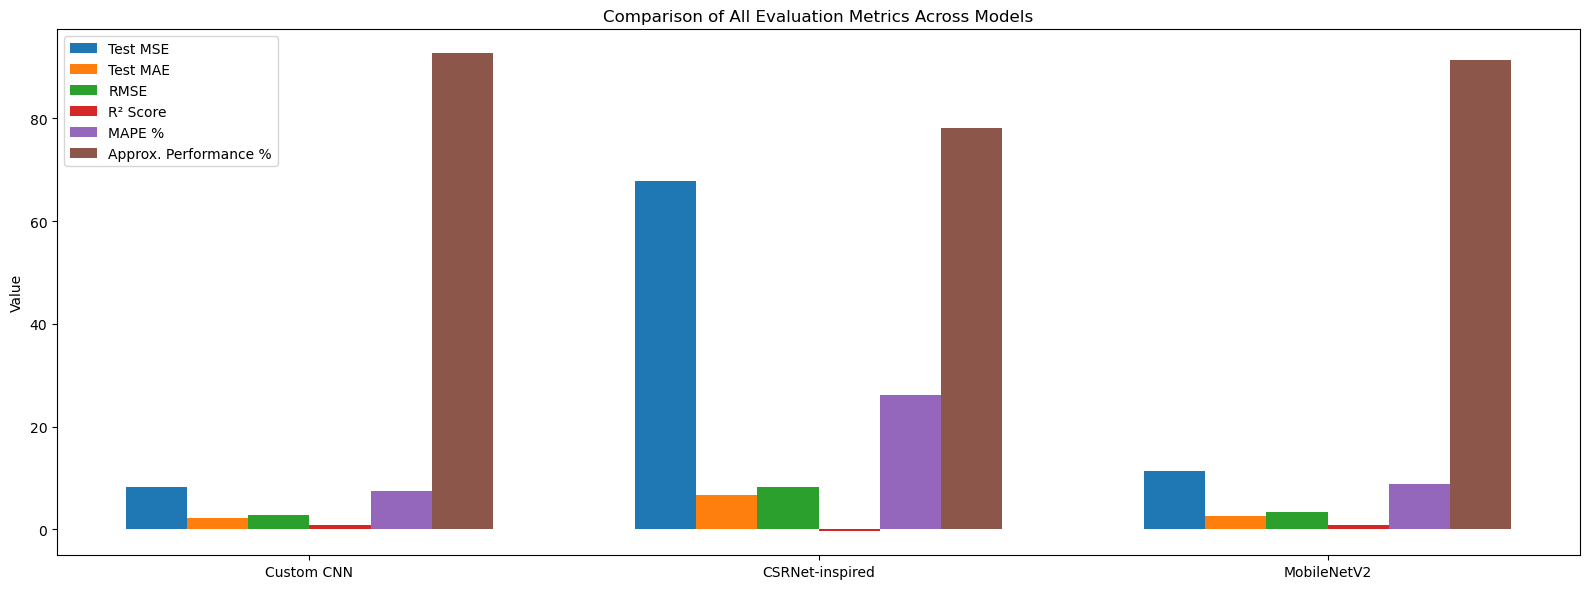

In [84]:
# ==========================================
# رسم جميع المقاييس في مخطط واحد مجمع
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

models = ['Custom CNN', 'CSRNet-inspired', 'MobileNetV2']

metrics_data = {
    'Test MSE': [test_loss, csr_test_loss, m_test_loss],
    'Test MAE': [test_mae, csr_test_mae, m_test_mae],
    'RMSE': [rmse, csr_rmse, m_rmse],
    'R² Score': [r2, csr_r2, m_r2],
    'MAPE %': [mape, csr_mape, m_mape],
    'Approx. Performance %': [approx_performance, csr_approx_performance, m_approx_performance]
}

x = np.arange(len(models))
width = 0.12

plt.figure(figsize=(16, 6))

for i, (metric_name, values) in enumerate(metrics_data.items()):
    plt.bar(x + i * width, values, width, label=metric_name)

plt.xticks(x + width * 2.5, models)
plt.ylabel("Value")
plt.title("Comparison of All Evaluation Metrics Across Models")
plt.legend()
plt.tight_layout()
plt.show()

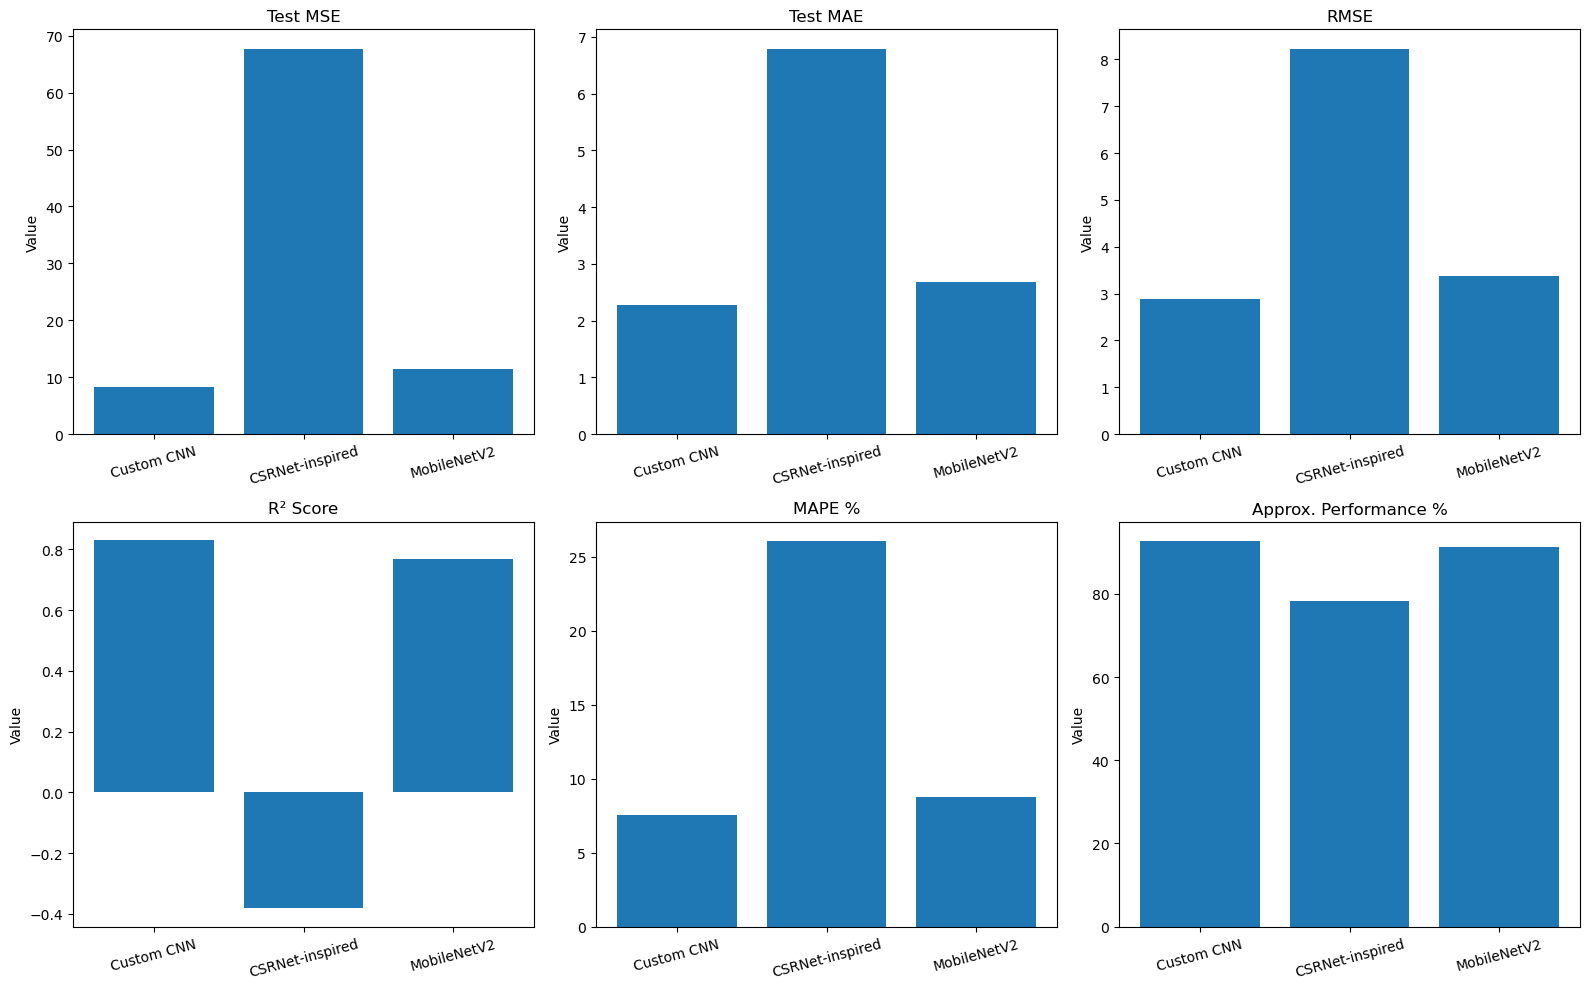

In [85]:
# ==========================================
# رسم جميع المقاييس لكل الخوارزميات في شكل واحد
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

# أسماء المودلات
models = ['Custom CNN', 'CSRNet-inspired', 'MobileNetV2']

# جميع المقاييس
test_mse_values = [test_loss, csr_test_loss, m_test_loss]
test_mae_values = [test_mae, csr_test_mae, m_test_mae]
rmse_values = [rmse, csr_rmse, m_rmse]
r2_values = [r2, csr_r2, m_r2]
mape_values = [mape, csr_mape, m_mape]
perf_values = [approx_performance, csr_approx_performance, m_approx_performance]

# أسماء المقاييس في قائمة واحدة
metrics = [
    ("Test MSE", test_mse_values),
    ("Test MAE", test_mae_values),
    ("RMSE", rmse_values),
    ("R² Score", r2_values),
    ("MAPE %", mape_values),
    ("Approx. Performance %", perf_values)
]

# إنشاء الرسم
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# تحويل axes إلى قائمة مسطحة حتى نسهل التكرار عليها
axes = axes.flatten()

# رسم كل مقياس في subplot مستقل
for i, (metric_name, values) in enumerate(metrics):
    axes[i].bar(models, values)
    axes[i].set_title(metric_name)
    axes[i].set_ylabel("Value")
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [86]:
#للتقرير


In [87]:
# ==========================================
# جدول ملخص البيانات
# ==========================================

dataset_summary = pd.DataFrame({
    "Item": [
        "Number of images",
        "Image shape",
        "Minimum count",
        "Maximum count",
        "Mean count",
        "Median count",
        "Standard deviation"
    ],
    "Value": [
        len(X),
        str(X.shape[1:]),
        int(y.min()),
        int(y.max()),
        round(y.mean(), 2),
        round(np.median(y), 2),
        round(y.std(), 2)
    ]
})

display(dataset_summary)

,Item,Value
0,Number of images,2000
1,Image shape,"(128, 128, 3)"
2,Minimum count,13
3,Maximum count,53
4,Mean count,31.16
5,Median count,31.0
6,Standard deviation,6.94


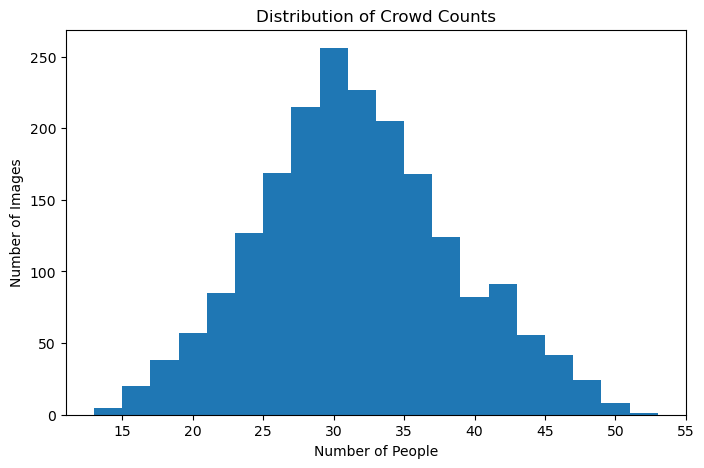

In [88]:
# ==========================================
# توزيع عدد الأشخاص في الصور
# ==========================================

plt.figure(figsize=(8,5))
plt.hist(y, bins=20)

plt.xlabel("Number of People")
plt.ylabel("Number of Images")
plt.title("Distribution of Crowd Counts")
plt.show()

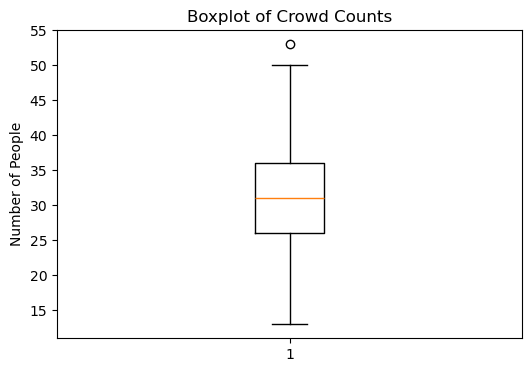

In [89]:
# ==========================================
# Boxplot لاكتشاف القيم الشاذة
# ==========================================

plt.figure(figsize=(6,4))
plt.boxplot(y)

plt.title("Boxplot of Crowd Counts")
plt.ylabel("Number of People")
plt.show()

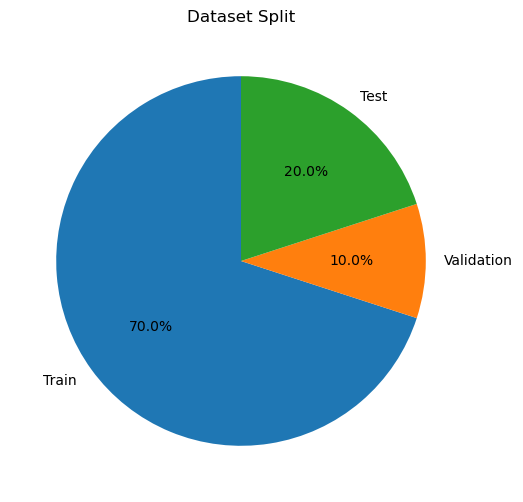

In [90]:
# ==========================================
# رسم دائري لتقسيم البيانات
# ==========================================

sizes = [len(X_train), len(X_val), len(X_test)]
labels = ['Train', 'Validation', 'Test']

plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title("Dataset Split")
plt.show()

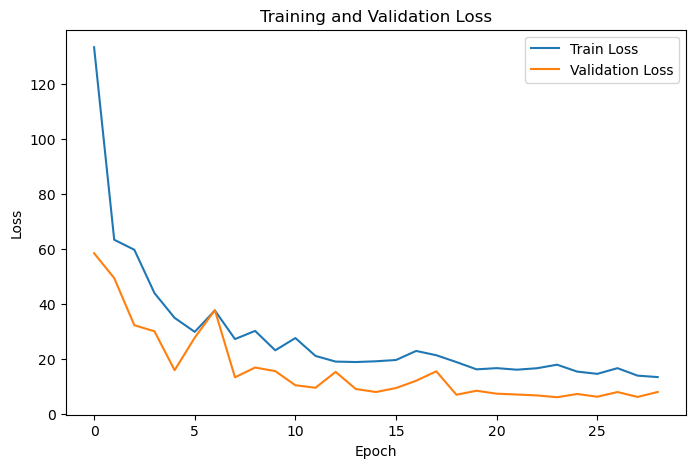

In [91]:
# ==========================================
# منحنى Loss
# ==========================================

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

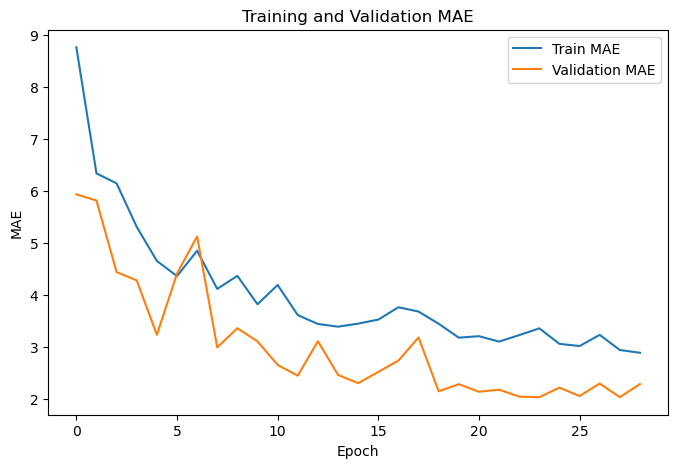

In [92]:
# ==========================================
# منحنى MAE
# ==========================================

plt.figure(figsize=(8,5))
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training and Validation MAE")
plt.legend()
plt.show()

In [93]:
# ==========================================
# جدول النتائج النهائية
# ==========================================

results_summary = pd.DataFrame({
    "Metric": ["Test MSE", "Test MAE", "RMSE", "R² Score", "MAPE %", "Approx. Performance %"],
    "Value": [
        round(test_loss, 2),
        round(test_mae, 2),
        round(rmse, 2),
        round(r2, 3),
        round(mape, 2),
        round(approx_performance, 2)
    ]
})

display(results_summary)

,Metric,Value
0,Test MSE,8.35
1,Test MAE,2.28
2,RMSE,2.89
3,R² Score,0.83
4,MAPE %,7.52
5,Approx. Performance %,92.68


In [94]:
# ==========================================
# مقارنة المودلات
# ==========================================

final_comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "CSRNet-inspired", "MobileNetV2"],
    "Test MSE": [round(test_loss, 2), round(csr_test_loss, 2), round(m_test_loss, 2)],
    "Test MAE": [round(test_mae, 2), round(csr_test_mae, 2), round(m_test_mae, 2)],
    "RMSE": [round(rmse, 2), round(csr_rmse, 2), round(m_rmse, 2)],
    "R² Score": [round(r2, 3), round(csr_r2, 3), round(m_r2, 3)],
    "MAPE %": [round(mape, 2), round(csr_mape, 2), round(m_mape, 2)],
    "Approx. Performance %": [
        round(approx_performance, 2),
        round(csr_approx_performance, 2),
        round(m_approx_performance, 2)
    ]
})

display(final_comparison_df)

,Model,Test MSE,Test MAE,RMSE,R² Score,MAPE %,Approx. Performance %
0,Custom CNN,8.35,2.28,2.89,0.830,7.52,92.68
1,CSRNet-inspired,67.74,6.79,8.23,-0.381,26.07,78.18
2,MobileNetV2,11.36,2.69,3.37,0.768,8.79,91.37
